In [22]:
import json
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
from scipy.ndimage import gaussian_filter, label, shift as nd_shift, zoom
from scipy import signal
import ipywidgets as widgets

print(f'Current working directory: {os.getcwd()}')

Current working directory: c:\Users\Rimehaug\Documents\projects\fUSI\FusiConverter


Change Working Directory

In [23]:
if Path().cwd().name == 'inspect-data-online':
    os.chdir(Path().cwd().parent)
print(f'Current working directory: {os.getcwd()}')

Current working directory: c:\Users\Rimehaug\Documents\projects\fUSI\FusiConverter


## Load Data

### Load registration data

In [24]:
session_date_id = '20251211-0'

filepath_areas_overview = list(Path('../data/'+session_date_id).glob('**/*HQ*areas*.json'))[0]
filepath_areas_voxel_hq_inds = list(Path('../data/'+session_date_id).glob('**/*HQ*areas*.npz'))[0]

with open(filepath_areas_overview, 'r') as file:
    areas_overview = json.load(file)

areas_voxel_hq_inds = np.load(filepath_areas_voxel_hq_inds)

hq_shape = areas_voxel_hq_inds['labels_shape']  # (hor, sag, coron) dims of the annotation volume

Get spatial dimensions of normal resolution image

In [25]:
print('Loading data...')

load_data_dir = Path('../data') / session_date_id

paths_mat = sorted([path for path in load_data_dir.glob('*GEY*/*.mat') if 'HQ' not in path.stem])

mat = sio.loadmat(paths_mat[0], squeeze_me=True)
I = mat['I'].astype(np.float32)
normal_resolution_dims = I.shape[:3]
has_signal = mat['I'].mean(axis=-1).ravel() > 0      # voxels outside the reconstructed field of view are 0
I.mean(axis=-1).ravel() > 0

Loading data...


array([ True,  True,  True, ..., False, False, False], shape=(241920,))

Map voxel indeces of high-quality image to voxel indeces of normal image for selected registered regions of the brain

In [26]:
def map_hq_inds_to_normal_inds(hor_inds, sag_inds, coron_inds, hq_shape, normal_shape, has_signal):
    """Map (hor, sag, coron) voxel indices from the HQ resolution grid onto the grid of the functional recording
    """
    mapped = []
    for inds, n_hq, n_func in zip((hor_inds, sag_inds, coron_inds), hq_shape, normal_shape):
        # print(inds, n_hq, n_func, inds + 0.5, (inds + 0.5)/n_hq * n_func, ((inds + 0.5)/n_hq * n_func).astype(int))
        # print(np.any(np.clip(((inds + 0.5)/n_hq * n_func).astype(int), 0, n_func - 1) != ((inds + 0.5)/n_hq * n_func).astype(int)))

        mapped.append(((inds + 0.5)/n_hq * n_func).astype(int))

    mapped = np.unique(np.stack(mapped), axis=1)
    return mapped[:, has_signal[np.ravel_multi_index(mapped, normal_shape)]]

In [27]:
region_patterns = {
    'VISp': r'^VISp\d',               # primary visual area, all layers
    'VIShigher': r'^VIS(?!C|p\d)',    # other visual areas (VISC is visceral, not visual)
    'SCs': r'^SC(zo|sg|op)$',         # superior colliculus, superficial (visual) layers
    'SCm': r'^SC(ig|iw|dg|dw)$',      # superior colliculus, motor-related layers
    'LGd': r'^LGd',
    'LP': r'^LP$',
    'RSP': r'^RSP',
    'AUD': r'^AUD',
    'SSp': r'^SSp',
    'MO': r'^MO[ps]',
    'CP': r'^CP$',
    'HPF': r'^(CA\d|DG)',
}

region_inds = {}
for name, pattern in region_patterns.items():
    print(name, pattern)
    ids = [str(structure['id']) for structure in areas_overview['structures'] if re.match(pattern, structure['acronym'])]
    hq_inds = np.unravel_index(np.concatenate([areas_voxel_hq_inds[i] for i in ids]), hq_shape)
    region_inds[name] = map_hq_inds_to_normal_inds(*hq_inds, hq_shape, normal_resolution_dims, has_signal)


ids = [str(structure['id']) for structure in areas_overview['structures'] if structure['division'] == 'Isocortex']
hq_inds = np.unravel_index(np.concatenate([areas_voxel_hq_inds[i] for i in ids]), hq_shape)
region_inds['Isocortex'] = map_hq_inds_to_normal_inds(*hq_inds, hq_shape, normal_resolution_dims, has_signal)

brain_hq_inds = np.unravel_index(np.concatenate([areas_voxel_hq_inds[key] for key in areas_voxel_hq_inds.files
                                                 if key != 'labels_shape']), hq_shape)
brain_inds = map_hq_inds_to_normal_inds(*brain_hq_inds, hq_shape, normal_resolution_dims, has_signal)

VISp ^VISp\d
VIShigher ^VIS(?!C|p\d)
SCs ^SC(zo|sg|op)$
SCm ^SC(ig|iw|dg|dw)$
LGd ^LGd
LP ^LP$
RSP ^RSP
AUD ^AUD
SSp ^SSp
MO ^MO[ps]
CP ^CP$
HPF ^(CA\d|DG)


### Load metadata

In [28]:
path_stim = list((load_data_dir / Path('GEY-P659-csv-files')).glob("*stimulus_timestamps*"))[0]
df_stim = pd.read_csv(path_stim, comment = '#')

path_enc = list((load_data_dir / Path('GEY-P659-csv-files')).glob("*encoder*"))[0]
df_enc = pd.read_csv(path_enc, comment='#')

path_frm = list((load_data_dir / Path('GEY-P659-csv-files')).glob("*frame_data*"))[0]
df_frm = pd.read_csv(path_frm, comment='#')


#### Get frame closest to stimulus presentations in each trials

In [29]:
frames_timestamps = np.stack([timestamps.to_numpy() for _, timestamps in df_frm.groupby('protocol_run')['timestamp']])
dt_frame = np.diff(frames_timestamps, axis=1).mean()
stim_duration_s = df_stim.loc[df_stim['pause'] == False, 'duration_ms'].mean() / 1000

inds_frame_closest_stim = []
absolute_timestamps_stims = []
for protocol_run, stim_group in df_stim.groupby('protocol_run'):
    idx_trial = int(protocol_run) - 1  # protocol_run is 1-indexed, frames_timestamps rows are 0-indexed
    stim_timestamps_trial = stim_group.loc[stim_group['pause'] == False, 'absolute_timestamp'].to_numpy()

    inds_frame_closest_stim_trial = []
    absolute_timestamps_stims_trial = []
    for stim_timestamp in stim_timestamps_trial:
        if frames_timestamps[idx_trial][0] <= stim_timestamp <= frames_timestamps[idx_trial][-1]:
            time_from_stim = frames_timestamps[idx_trial] - stim_timestamp
            inds_frame_closest_stim_trial.append(len(time_from_stim[time_from_stim < 0]))
            absolute_timestamps_stims_trial.append(stim_timestamp)
    inds_frame_closest_stim.append(inds_frame_closest_stim_trial)
    absolute_timestamps_stims.extend(absolute_timestamps_stims_trial)

df_frame_stim_onset = (pd.DataFrame(inds_frame_closest_stim)
                       .rename_axis(index='trial', columns='stim_nr')
                       .stack()
                       .dropna()
                       .astype(int)
                       .rename('onset_frame')
                       .reset_index() 
)
df_frame_stim_onset['absolute_timestamp_stims'] = absolute_timestamps_stims
# keep only events whose whole epoch lies inside the recorded frames
n_frames = frames_timestamps.shape[1]
df_frame_stim_onset

,trial,stim_nr,onset_frame,absolute_timestamp_stims
0,0,0,12,18.593115
1,0,1,30,23.693395
2,0,2,48,28.592770
3,0,3,66,33.692306
4,0,4,84,38.592074
...,...,...,...,...
296,59,0,11,3557.990363
297,59,1,29,3563.090142
298,59,2,47,3567.990001
299,59,3,65,3573.089829


## Load recorded data for whole brain and for each selected region

In [30]:
# indeces of whole brain
hor_inds, sag_inds, coron_inds = brain_inds

regions_signal = {}
for region_name in region_inds.keys():
    regions_signal[region_name] = []

# load the recorded data in each trial and 
whole_brain_signal = []
for i, path_mat in enumerate(paths_mat):
    mat = sio.loadmat(path_mat, squeeze_me=True)
    I = mat['I'].astype(np.float32)
    print(f'Trial nr. {path_mat.stem.split('_')[-1]}, Image dimensions: {I.shape}', I[hor_inds, sag_inds, coron_inds].shape)
    whole_brain_signal.append(I[hor_inds, sag_inds, coron_inds])

    for region_name in region_inds.keys():
        hor_reg_inds, sag_reg_inds, coron_reg_inds = region_inds[region_name]

        regions_signal[region_name].append(I[hor_reg_inds, sag_reg_inds, coron_reg_inds])

whole_brain_signal = np.asarray(whole_brain_signal)

Trial nr. 0, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 1, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 2, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 3, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 4, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 5, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 6, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 7, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 8, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 9, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 10, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 11, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 12, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 13, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 14, Image dimensions: (70, 64, 54, 100) (139106, 100)
Trial nr. 15, Image dimensions: (70, 64, 54, 100) 

### Plot

In [31]:
region_checkboxes = {
    name: widgets.Checkbox(value=False, description=name, indent=False)
    for name in regions_signal.keys()
}

select_regions_widget = widgets.GridBox(
    list(region_checkboxes.values()),
    layout=widgets.Layout(grid_template_columns='repeat(4, 150px)')
)
select_regions_widget

GridBox(children=(Checkbox(value=False, description='VISp', indent=False), Checkbox(value=False, description='…

In [32]:
selected_region_names = [name for name, checkbox in region_checkboxes.items() if checkbox.value]
selected_region_names

['VISp', 'SCs', 'LGd', 'SSp']

In [33]:
colors = ['b', 'tab:orange', 'g', 'r', 'c', 'm', 'y', 'k', 'tab:brown', 'gold', 'fuchsia', 'crimson', 'blueviolet']


regions_colors = {}

for i, region_name in enumerate(regions_signal.keys()):
    regions_colors[region_name] = colors[i]


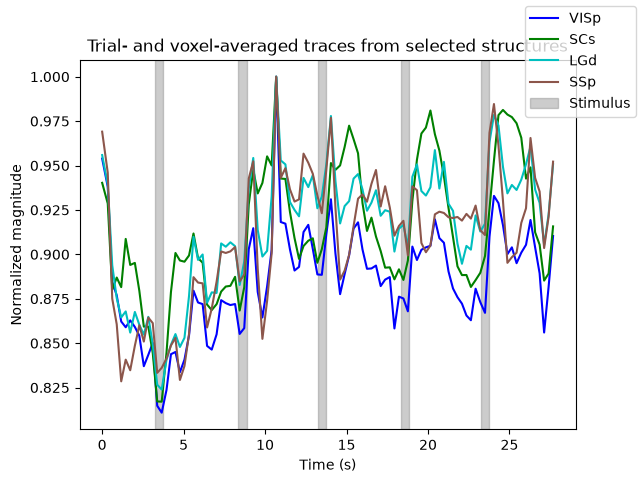

In [34]:
time_trial_onset = df_frm[df_frm['protocol_run'] == 1]['timestamp'].values[0]

trial_time_plot = df_frm[df_frm['protocol_run'] == 1]['timestamp'].values - time_trial_onset

fig, axes = plt.subplots()

for region_name in selected_region_names: #region_signal.keys():
    region_signal = np.array(regions_signal[region_name])
    I_plot = region_signal.mean(axis=(0,1)) / region_signal.mean(axis=(0,1)).max()
    axes.plot(trial_time_plot, I_plot, label=region_name, color=regions_colors[region_name])

#plt.plot(trial_time_plot, I_brain_plot, label='Whole Brain')

axes.set_title('Trial- and voxel-averaged traces from selected structures')
axes.set_ylabel('Normalized magnitude')
axes.set_xlabel('Time (s)')

# stimulus presentations of protocol run 1 (trial 0), on the same clock as its frame timestamps
for istim, t_stim in enumerate(df_frame_stim_onset.loc[df_frame_stim_onset['trial'] == 0, 'absolute_timestamp_stims']):
    plt.axvspan(t_stim - time_trial_onset, t_stim - time_trial_onset + stim_duration_s, color='gray', alpha=0.4, label='Stimulus' if istim == 0 else None)

fig.legend()


# save figure

# path for figures
output_dir = Path('fUSI_analysis_from_thoralf/figures')
output_dir.mkdir(exist_ok=True, parents=True)

fig_name = Path(f'session_{session_date_id}_oddball_visual_response.png')

# fig.savefig(output_dir / fig_name)


## Coronal-plane maps of the `voxel_groups` regions

For a few coronal planes, show where each region's voxels are.

fUSI_analysis_from_thoralf\figures\voxel_groups_coronal_planes.png


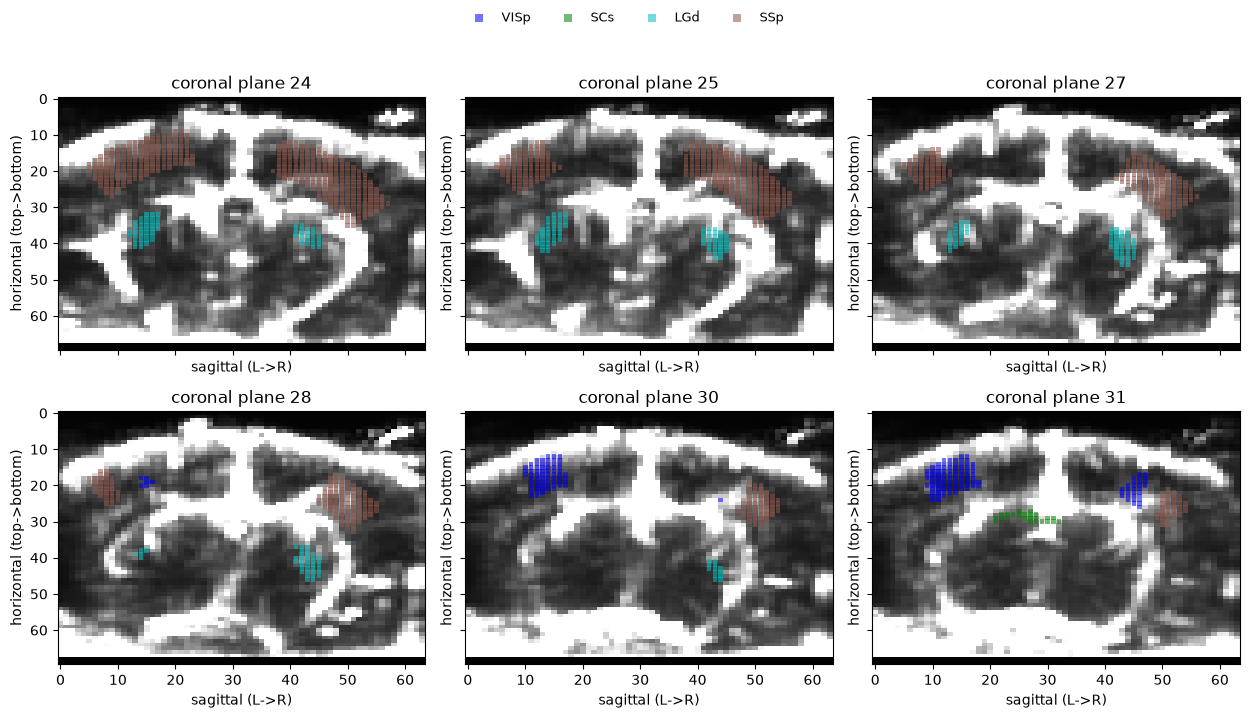

In [35]:
# plot the regions on the coronal planes that hold the most region voxels

all_region_voxel_inds = np.concatenate([np.asarray(inds) for inds in region_inds.values()], axis=1)

n_planes_to_plot = 6
inds_coron_plane, count_inds_coron_plane = np.unique(all_region_voxel_inds[2], return_counts=True)
inds_coron_plane_plot = np.sort(inds_coron_plane[np.argsort(count_inds_coron_plane)[-n_planes_to_plot:]])

# time-averaged image of the last loaded trial as anatomical background
I_mean = I.mean(axis=-1)

ncols = 3
nrows = int(np.ceil(len(inds_coron_plane_plot) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.6 * nrows),
                        sharex=True, sharey=True, squeeze=False)

for ax, idx_coron_plane in zip(axes.flat, inds_coron_plane_plot):
    image_brain = I_mean[:, :, idx_coron_plane]
    ax.imshow(image_brain, aspect='auto', cmap='gray', vmin=0, vmax=np.percentile(image_brain, 80))
    for region_name in selected_region_names:
        hor_reg_inds, sag_reg_inds, coron_reg_inds = region_inds[region_name]
        mask_coron_plane = coron_reg_inds == idx_coron_plane
        ax.scatter(sag_reg_inds[mask_coron_plane], hor_reg_inds[mask_coron_plane], s=10, marker='s', alpha=0.55,
                   color=regions_colors[region_name], edgecolors='none', label=region_name)
    ax.set_title(f'coronal plane {idx_coron_plane}')
    ax.set_xlabel('sagittal (L->R)')
    ax.set_ylabel('horizontal (top->bottom)')

for ax in axes.flat[len(inds_coron_plane_plot):]:
    ax.axis('off')

handles, labels_ = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='upper center', ncol=int(np.ceil(len(region_inds) / 2)),
           fontsize=9, markerscale=1.8, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.92))  # leave room for the legend above the panels

filename = Path('voxel_groups_coronal_planes.png')
print(output_dir / filename)
# fig.savefig(output_dir / filename, bbox_inches='tight')

## 3D view of the selected regions

Transparent brain surface with the regions picked in the checkbox widget drawn as colored surfaces. Drag to rotate, scroll to zoom, click a legend entry to hide/show it.

In [36]:
import plotly.graph_objects as go
from matplotlib.colors import to_hex
from skimage.measure import marching_cubes

# surfaces are extracted with marching cubes from (lightly smoothed) binary voxel masks
voxel_size = np.asarray(mat['metadata']['voxelSize'].item(), dtype=float)  # mm per voxel along (hor, sag, coron)

def mask_to_mesh(inds, name, color, opacity, sigma=0.8):
    """Build a Mesh3d surface around the voxels in `inds` (hor, sag, coron), in mm."""
    mask = np.zeros(normal_resolution_dims, dtype=np.float32)
    mask[tuple(inds)] = 1
    mask = np.pad(gaussian_filter(mask, sigma), 1)  # pad so surfaces close at the volume edges
    if mask.max() < 0.5:
        return None
    verts, faces, _, _ = marching_cubes(mask, level=0.5, spacing=tuple(voxel_size))
    verts -= voxel_size  # undo the padding offset
    hor, sag, coron = verts.T
    return go.Mesh3d(x=sag, y=coron, z=-hor,  # flip horizontal axis so dorsal is up
                     i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
                     color=color, opacity=opacity, name=name, showlegend=True,
                     lighting=dict(ambient=0.5, diffuse=0.8, specular=0.2))

meshes = [mask_to_mesh(brain_inds, 'Brain', 'lightgray', opacity=0.8, sigma=1.5)]
for region_name in selected_region_names:
    meshes.append(mask_to_mesh(region_inds[region_name], region_name, to_hex(regions_colors[region_name]), opacity=0.7))

fig_3d = go.Figure([mesh for mesh in meshes if mesh is not None])
fig_3d.update_layout(
    title='Selected regions in 3D',
    scene=dict(xaxis_title='sagittal, L->R (mm)',
               yaxis_title='coronal, nose->neck (mm)',
               zaxis_title='horizontal, ventral->dorsal (mm)',
               aspectmode='data'),
    width=900, height=700, margin=dict(l=0, r=0, t=40, b=0),
)
fig_3d.show()

# fig_3d.write_html(output_dir / f'session_{session_date_id}_regions_3d.html')